# Notebook 2 — Nodule Segmentation & Feature Extraction
**Lab IA & CD – Project 1 | Lung Nodule Malignancy on CT (LNDb + LIDC-IDRI)**

---

## Purpose
Turn each nodule (a small 3D region of a CT scan) into a row of numbers a model can learn from.

## The key constraint
The competition test set only gives the **centroid** of each finding — no segmentation.
If we trained on features computed inside the radiologists' masks and then tested on
something else, the model would see different kinds of data at training and test time.

So **every nodule, train and test, is processed in exactly the same way**:

```
CT scan ──► 48 mm box around the centroid ──► automatic segmentation ──► features
```

## Creative angle — how much do we lose without a radiologist?
For training nodules we also have the radiologist's mask. We use it to:
1. **Measure the quality** of our automatic segmentation (Dice overlap).
2. Extract a **second set of features inside the radiologist's mask**. Notebook 4 compares
   both: the gap tells us the price of a fully automatic system.

## Where the code lives
The segmentation and extraction code is in `lndb_features.py` (documented function by
function). It runs one CT per CPU core in parallel and caches results, so this notebook
stays focused on **explaining and checking** the process.

**Inputs:** `outputs/working_dataset.csv` (Notebook 1), CT scans, masks, `testNodules.csv`
**Outputs:** `outputs/features_train.csv`, `outputs/features_train_radiologist.csv`, `outputs/features_test.csv`

---

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import SimpleITK as sitk

import lndb_utils as U        # paths, classes, colours
import lndb_features as F     # segmentation + feature extraction

plt.rcParams.update(U.PLOT_STYLE)

# ── Run settings ──────────────────────────────────────────────────────────────
N_JOBS          = -1      # CPU cores to use (-1 = all)
FORCE_RECOMPUTE = False   # True → delete cached results (needed after changing lndb_features.py)
# ─────────────────────────────────────────────────────────────────────────────

if FORCE_RECOMPUTE:
    import shutil
    shutil.rmtree(U.OUTPUT_DIR / 'cache', ignore_errors=True)
print('Setup complete.')

Setup complete.


## 2. Inputs

In [2]:
nodules  = pd.read_csv(U.OUTPUT_DIR / 'working_dataset.csv')
test_nod = pd.read_csv(U.TEST_CSV_DIR / 'testNodules.csv')

train_index = U.build_ct_index(U.TRAIN_IMAGE_DIRS)
test_index  = U.build_ct_index(U.TEST_IMAGE_DIRS)

missing_train = sorted(set(nodules.LNDbID) - set(train_index))
missing_test  = sorted(set(test_nod.LNDbID) - set(test_index))

print(f'Train: {nodules.LNDbID.nunique()} CTs needed, {nodules.LNDbID.nunique() - len(missing_train)} found')
print(f'Test : {test_nod.LNDbID.nunique()} CTs needed, {test_nod.LNDbID.nunique() - len(missing_test)} found')
if missing_train:
    print(f'⚠️  Missing train CTs: {missing_train}  → their nodules will be skipped')
if missing_test:
    print(f'⚠️  Missing test CTs : {missing_test}  → their findings get no prediction')

Train: 212 CTs needed, 212 found
Test : 58 CTs needed, 58 found


## 3. How the automatic segmentation works
A single fixed threshold does not work: a ground-glass nodule (≈ −700 HU) is barely denser
than the lung around it (≈ −850 HU), while a solid nodule is ≈ 0 HU and a calcified one can
exceed +1000 HU. The algorithm (`F.segment_nodule`) therefore adapts to each nodule:

| Step | What it does | Why |
|---|---|---|
| a. Smooth | Light Gaussian filter (0.5 mm) | Reduce CT noise |
| b. Adaptive threshold | Halfway (α = 0.3) between nodule core and surrounding lung | Works for faint GGO and dense solid nodules alike |
| c. Lung mask | Keep only voxels inside the lung | Stops nodules touching the chest wall from leaking into muscle/ribs |
| d. Leak control | Keep the region at the centroid; if it reaches 20 mm, cut thin links (vessels) with a growing morphological opening | Nodules are often attached to vessels |
| e. Fallback | 3 mm sphere if nothing is found | Every finding gets features |

The parameters (α, lung-closing radius) were chosen by comparing against radiologist masks
on a development sample of 24 nodules: adding the lung mask raised the mean Dice from
≈0.46 to ≈0.56 and removed most of the failures, which were nodules touching the chest wall.

Below, one nodule of each texture class, step by step.

In [3]:
def load_example(row):
    """CT patch, radiologist mask patch, centre and spacing for one training nodule."""
    ct = sitk.ReadImage(str(train_index[row.LNDbID]))
    vol = sitk.GetArrayFromImage(ct)
    sx, sy, sz = ct.GetSpacing(); sp = (sz, sy, sx)
    ix, iy, iz = ct.TransformPhysicalPointToIndex((row.x, row.y, row.z))
    patch, c = F.crop_patch(vol, (iz, iy, ix), sp)
    rmask = sitk.GetArrayFromImage(sitk.ReadImage(str(U.mask_path(row.LNDbID, row.mask_rad_id))))
    rmask, _ = F.crop_patch(rmask, (iz, iy, ix), sp)
    return patch, rmask == row.mask_finding_id, c, sp

available = nodules[nodules.LNDbID.isin(train_index) & ~nodules.is_small]
examples = [available[available.texture_class == k].sample(1, random_state=U.RANDOM_STATE).iloc[0]
            for k in range(3)]

fig, axes = plt.subplots(3, 4, figsize=(14, 10.5))
for i, row in enumerate(examples):
    patch, rmask, c, sp = load_example(row)
    auto, status, steps = F.segment_nodule(patch, c, sp, return_steps=True)
    z = c[0]
    panels = [
        (patch[z], None, f'{U.CLASS_NAMES[row.texture_class]} — CT (LNDb-{row.LNDbID:04d})'),
        (steps['lung'][z], None, 'c. lung mask'),
        (steps['candidate'][z], None, f'b. threshold {steps["threshold"]:.0f} HU'),
        (patch[z], auto[z], f'auto (red) vs radiologist (green)\nDice = {F.dice(auto, rmask):.2f}'),
    ]
    for ax, (img, seg, title) in zip(axes[i], panels):
        is_ct = img.dtype != bool
        ax.imshow(img, cmap='gray', vmin=-1000 if is_ct else 0, vmax=400 if is_ct else 1)
        if seg is not None:
            ax.contour(rmask[z], [0.5], colors='lime', linewidths=1.2)
            ax.contour(seg, [0.5], colors='red', linewidths=1.2)
        ax.plot(c[2], c[1], 'y+', ms=10)
        ax.set_title(title, fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

> **Public version:** the figure of example CT patches produced by the cell above is not included here. LNDb images are licensed CC BY-NC-ND 4.0 and may not be redistributed; run the notebook with your own copy of LNDb to see it.

## 4. Feature extraction
For every nodule, `F.process_ct` computes two groups of features inside the segmentation.

### Radiomic features — pyradiomics, 1130
The CT is first resampled to 1 × 1 × 1 mm, so features do not depend on each scanner's voxel
size. Features are then computed on **12 versions of the image**, each highlighting different
structures:

| Image version | Count | What it highlights |
|---|---|---|
| Original | 107 | The CT as acquired (incl. 14 shape features, computed once) |
| Wavelet × 8 (LLL, LLH, …, HHH) | 8 × 93 | Low (L) / high (H) frequencies along x, y, z — fine texture and edges vs smooth density |
| Laplacian of Gaussian, σ = 1, 2, 3 mm | 3 × 93 | Blobs and edges of increasing size — fine to coarse texture |
| **Total** | **1130** | |

The 93 features computed on each version belong to six families:

| Family | Describes | Example |
|---|---|---|
| First order (18) | Distribution of HU values | Mean, 90th percentile, skewness |
| GLCM (24), GLRLM (16), GLSZM (16), GLDM (14), NGTDM (5) | Texture: how intensities are arranged | Contrast, homogeneity, zone size |

Names follow `rad_<image version>_<family>_<feature>`, e.g. `rad_wavelet-HLL_glcm_Contrast`.

### Composition features — our own, 6
Radiologists call a nodule part-solid when it mixes a solid component (> −300 HU) with
ground-glass (−750 to −300 HU). We measure exactly that: solid fraction, ground-glass fraction,
solid volume, median HU of the core, 90th percentile HU and total volume. They are few,
interpretable, and directly tied to the clinical definition.

### Why so many features — and the consequence
A large, standardised feature bank makes sure no useful pattern is missed. But **1136 features
for ~770 nodules** means more features than examples: many are redundant (the same texture
measured on similar filtered images) and a model trained on all of them would overfit.
Reducing them is the job of Notebook 3.

Results are cached per CT in `outputs/cache/`; re-running only processes missing CTs.

In [4]:
%%time
train_raw = F.extract_features(nodules, train_index, split='train', with_radiologist=True, n_jobs=N_JOBS)
test_raw  = F.extract_features(test_nod, test_index, split='test', n_jobs=N_JOBS)

print(f'\nTrain rows: {len(train_raw)}  ({train_raw.roi.value_counts().to_dict()})')
print(f'Test rows : {len(test_raw)}')
for name, res in [('train', train_raw), ('test', test_raw)]:
    if res.attrs.get('failed_cts'):
        print(f'⚠️  {name} CTs that could not be read (re-extract them and re-run): {res.attrs["failed_cts"]}')


Train rows: 1393  ({'auto': 768, 'radiologist': 625})
Test rows : 2900
CPU times: user 6.01 s, sys: 670 ms, total: 6.68 s
Wall time: 6min 41s


## 5. How good is the automatic segmentation?

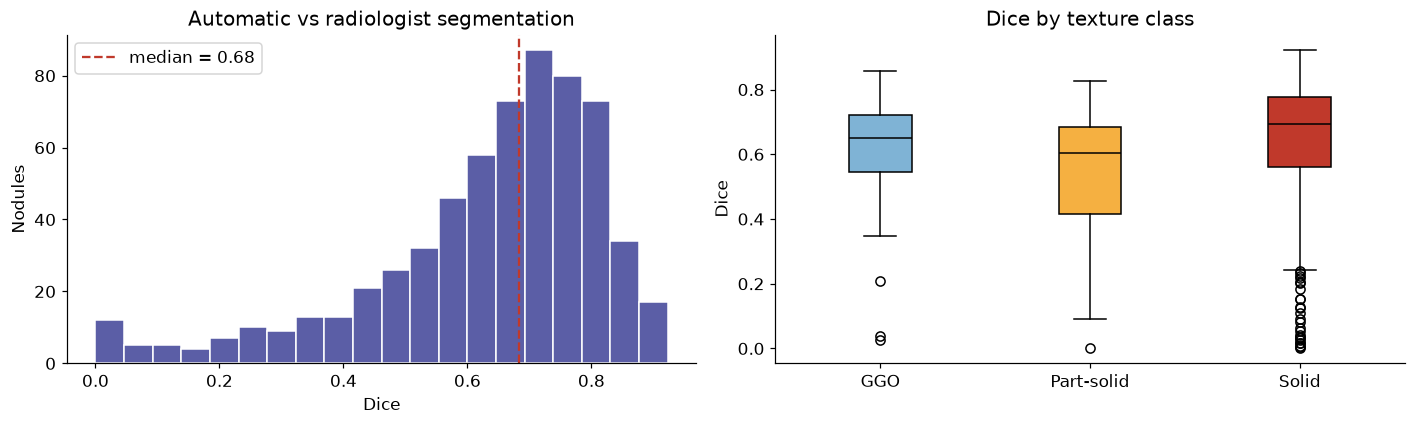

Segmentation outcome (all train nodules): {'ok': 691, 'clipped': 74, 'fallback': 3}


,count,mean,50%
texture_name,,,
GGO,33.0,0.593,0.651
Part-solid,55.0,0.538,0.603
Solid,537.0,0.643,0.692
All,625.0,0.631,0.682


In [5]:
auto = train_raw[train_raw.roi == 'auto'].merge(
    nodules[['LNDbID', 'FindingID', 'texture_name', 'is_small']], on=['LNDbID', 'FindingID'])
seg = auto[~auto.is_small & auto.dice_vs_radiologist.notna()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(seg.dice_vs_radiologist, bins=20, color=U.COLOR_NEUTRAL, edgecolor='white')
axes[0].axvline(seg.dice_vs_radiologist.median(), color=U.COLOR_ACCENT, ls='--',
                label=f'median = {seg.dice_vs_radiologist.median():.2f}')
axes[0].set(title='Automatic vs radiologist segmentation', xlabel='Dice', ylabel='Nodules'); axes[0].legend()

data = [seg.loc[seg.texture_name == c, 'dice_vs_radiologist'] for c in U.CLASS_NAMES]
box = axes[1].boxplot(data, tick_labels=U.CLASS_NAMES, patch_artist=True, medianprops=dict(color='black'))
for patch, c in zip(box['boxes'], U.CLASS_NAMES):
    patch.set_facecolor(U.CLASS_COLORS[c])
axes[1].set(title='Dice by texture class', ylabel='Dice')
plt.tight_layout(); plt.show()

summary = seg.groupby('texture_name')['dice_vs_radiologist'].describe()[['count', 'mean', '50%']]
summary.loc['All'] = seg.dice_vs_radiologist.describe()[['count', 'mean', '50%']]
print('Segmentation outcome (all train nodules):', auto.seg_status.str.replace(r'open.*', 'ok', regex=True).value_counts().to_dict())
summary.round(3)

**Reading the results.** Dice measures overlap: 1 = identical, 0 = no overlap. For small
nodules Dice is a harsh metric — a one-voxel shift on a 4 mm nodule already costs a lot.
Remember also that radiologists themselves do not draw identical contours.

The segmentation does not need to be perfect: what matters is whether the features it
produces still carry the information the radiologists rate (malignancy, texture). Notebook 4
answers that by comparing the same malignancy model trained on automatic vs radiologist
segmentations.

## 6. Feature quality

In [6]:
meta_cols = ['LNDbID', 'FindingID', 'roi', 'seg_status', 'dice_vs_radiologist', 'error']
feat_cols = [c for c in train_raw.columns if c not in meta_cols]

n_err_train = (train_raw.seg_status == 'error').sum()
n_err_test  = (test_raw.seg_status == 'error').sum()
print(f'Extraction errors — train: {n_err_train}, test: {n_err_test}')
if 'error' in train_raw and n_err_train:
    print(train_raw.loc[train_raw.seg_status == 'error', 'error'].value_counts().head())

train_ok = train_raw[train_raw.seg_status != 'error']
nan_cols   = [c for c in feat_cols if train_ok[c].isna().any()]
const_cols = [c for c in feat_cols if train_ok[c].nunique() <= 1]
print(f'Features: {len(feat_cols)} | with NaN: {len(nan_cols)} | constant: {len(const_cols)}')

Extraction errors — train: 0, test: 16
Features: 1136 | with NaN: 0 | constant: 0


In [7]:
# Remove constant features (no information) and features with missing values
drop = sorted(set(nan_cols) | set(const_cols))
feat_cols = [c for c in feat_cols if c not in drop]
print(f'Dropped {len(drop)} features → {len(feat_cols)} remain')
if drop:
    print('  ', drop)

Dropped 0 features → 1136 remain


### Do the composition features separate the classes?
A first sanity check before any modelling: if our features are meaningful, the solid
fraction should increase from GGO to part-solid to solid.

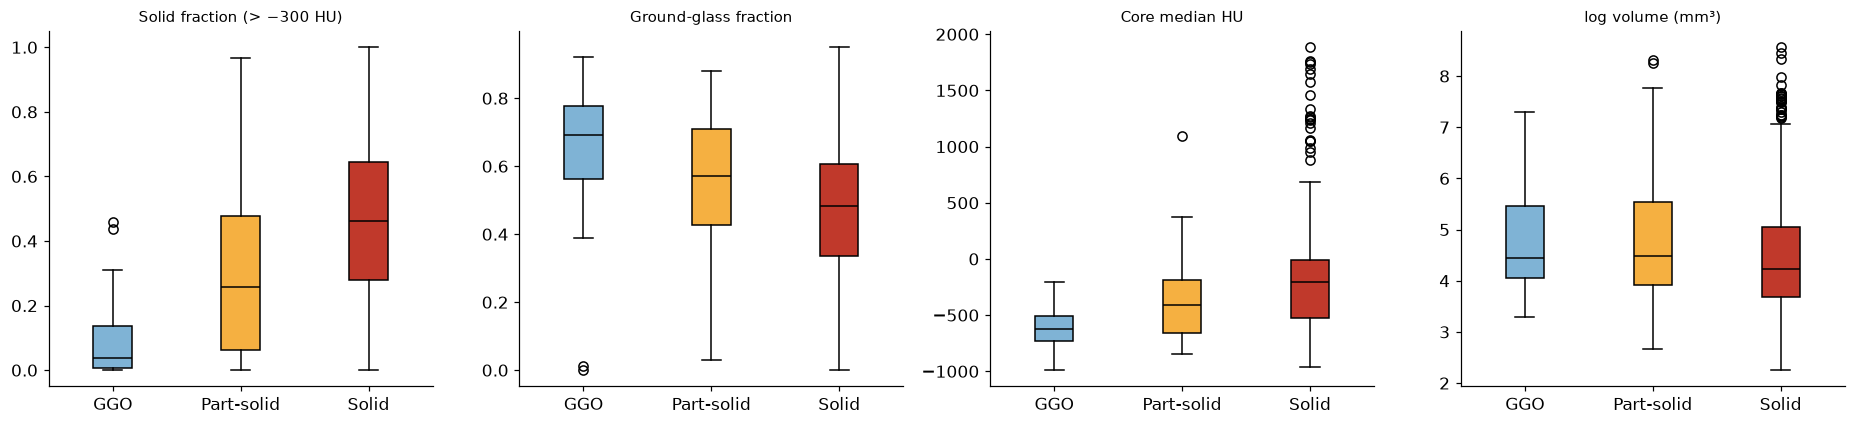

,comp_solid_fraction,comp_ggo_fraction,comp_core_hu_median,comp_volume_log
texture_name,,,,
GGO,0.04,0.69,-625.0,4.45
Part-solid,0.26,0.57,-412.5,4.48
Solid,0.46,0.48,-206.0,4.22


In [8]:
auto_ok = auto[auto.seg_status != 'error']
cols = ['comp_solid_fraction', 'comp_ggo_fraction', 'comp_core_hu_median', 'comp_volume_log']
titles = ['Solid fraction (> −300 HU)', 'Ground-glass fraction', 'Core median HU', 'log volume (mm³)']

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col, title in zip(axes, cols, titles):
    box = ax.boxplot([auto_ok.loc[auto_ok.texture_name == c, col] for c in U.CLASS_NAMES],
                     tick_labels=U.CLASS_NAMES, patch_artist=True, medianprops=dict(color='black'))
    for patch, c in zip(box['boxes'], U.CLASS_NAMES):
        patch.set_facecolor(U.CLASS_COLORS[c])
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

auto_ok.groupby('texture_name')[cols].median().reindex(U.CLASS_NAMES).round(2)

## 7. Save the feature tables

In [9]:
label_cols = ['LNDbID', 'FindingID', 'fold', 'texture_class', 'texture_name', 'Text', 'is_small']
keep = ['LNDbID', 'FindingID', 'seg_status'] + feat_cols

def build_train(roi: str) -> pd.DataFrame:
    t = train_raw[(train_raw.roi == roi) & (train_raw.seg_status != 'error')][keep]
    if roi == 'auto':
        t = t.merge(train_raw[train_raw.roi == 'auto'][['LNDbID', 'FindingID', 'dice_vs_radiologist']],
                    on=['LNDbID', 'FindingID'])
    return nodules[label_cols].merge(t, on=['LNDbID', 'FindingID'])

features_train     = build_train('auto')
features_train_rad = build_train('radiologist')
features_test      = test_raw[keep]          # errors kept: they still need a prediction

features_train.to_csv(U.OUTPUT_DIR / 'features_train.csv', index=False)
features_train_rad.to_csv(U.OUTPUT_DIR / 'features_train_radiologist.csv', index=False)
features_test.to_csv(U.OUTPUT_DIR / 'features_test.csv', index=False)

for name, t in [('features_train.csv', features_train),
                ('features_train_radiologist.csv', features_train_rad),
                ('features_test.csv', features_test)]:
    print(f'{name:<32} {t.shape[0]:>5} rows × {t.shape[1]} columns')

features_train.csv                 768 rows × 1145 columns
features_train_radiologist.csv     625 rows × 1144 columns
features_test.csv                 2900 rows × 1139 columns


---
## Summary

| Decision | Reason |
|---|---|
| Same automatic segmentation for train and test | The test set has no masks; train and test features must be comparable |
| Adaptive threshold (α = 0.3) | GGO and solid nodules have very different densities |
| Lung mask before segmenting | Stops leaks into the chest wall — the main failure mode |
| Progressive opening | Detaches nodules from vessels without eroding small nodules |
| Resampling to 1 mm isotropic | Features independent of each scanner's voxel size |
| pyradiomics on original + wavelet + LoG images (1130) | Standardised, comprehensive feature bank (~1000 features as required) |
| 6 composition features | Interpretable, tied to the clinical definition of texture |
| Radiologist-mask features kept separately | Measures the cost of full automation (Notebook 4) |
| Per-CT cache + parallel jobs | Interrupted runs resume; extraction takes minutes |

**Next → Notebook 3:** select the most informative features.

In [10]:
import pandas as pd
import lndb_utils as U

features_train = pd.read_csv(U.OUTPUT_DIR / 'features_train.csv')

rad_cols  = [c for c in features_train.columns if c.startswith('rad_')]
comp_cols = [c for c in features_train.columns if c.startswith('comp_')]

print(f'Nódulos     : {len(features_train)}')
print(f'pyradiomics : {len(rad_cols)}')
print(f'composition : {len(comp_cols)}')
print(f'TOTAL       : {len(rad_cols) + len(comp_cols)}\n')

por_imagem = pd.Series([c.split('_')[1] for c in rad_cols]).value_counts().sort_index()
por_imagem

Nódulos     : 768
pyradiomics : 1130
composition : 6
TOTAL       : 1136



log-sigma-1-0-mm-3D     93
log-sigma-2-0-mm-3D     93
log-sigma-3-0-mm-3D     93
original               107
wavelet-HHH             93
wavelet-HHL             93
wavelet-HLH             93
wavelet-HLL             93
wavelet-LHH             93
wavelet-LHL             93
wavelet-LLH             93
wavelet-LLL             93
Name: count, dtype: int64